# Leer antes de empezar

Tenéis dos horas para resolver los tres ejercicios. Si no podéis resolver alguno, **dejadlo para el final y continuad** con el siguiente. Los ejercicios tienen diferentes niveles de dificultad, os recomendamos leerlos **todos** antes de empezar con uno de ellos. Puede que algunos os suenen, es posible que tengan algún cambio.

Resolver un examen no se limita a realizar todos los ejercicios correctamente (no siempre lo conseguimos!), también depende de saber estratégicamente en qué ejercicios y apartados invertir más o menos tiempo del examen para maximizar la puntuación.

Ánimo y mucha suerte!

# Ejercicio 1

Basandote en lo que aprendimos durante P1, crea una imagen RGB de 300x300 con tres columnas del mismo ancho que sigan los colores RGB. Luego, carga la imagen `star_500.png` y utilízala para modificar la primera imagen incrustando una **estrella amarilla invertida** en ella. Finalmente, muestra la imagen original, la imagen `star_500`, la imagen con la estrella amarilla incrustada y una versión en escala de grises. Los resultados finales deberían verse como sigue:

![](E1_SideA.png)

**Consejos útiles:**

- `rgb2gray` devuelve una imagen de tipo float en el rango [0, 1]; es posible que quieras devolverla al rango [0, 255]. Una simple multiplicación debería bastar.

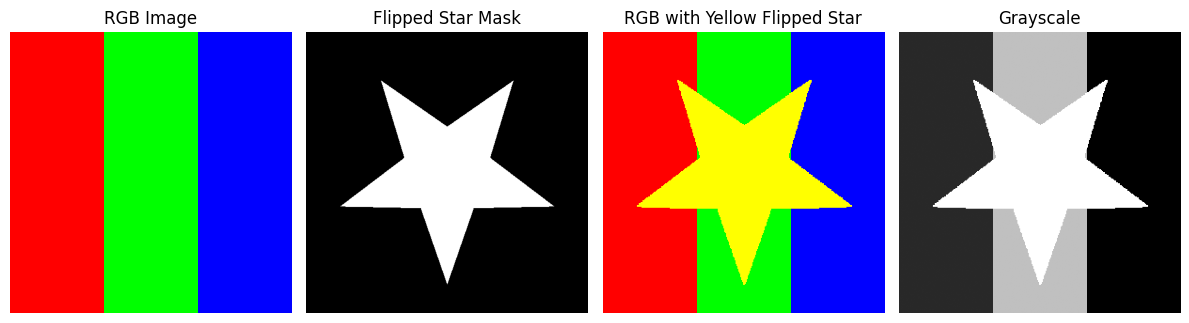

In [61]:
import numpy as np
import matplotlib.image as mpimg
from skimage import io
from skimage.transform import resize
from skimage.color import rgb2gray
from matplotlib import pyplot as plt

rgb_image = np.zeros((300, 300, 3), dtype=np.uint8) # Crear imagen 300 x 300

# Pintar las franjas de distintos colores (RGB)
rgb_image[:, :100] = [255, 0, 0]
rgb_image[:, 100:200] = [0, 255, 0]
rgb_image[:, 200:] = [0, 0, 255]

star_mask = mpimg.imread("star_500.png") # Cargar imagen de estrella
star_mask = star_mask[::-1, :] # Flipear la estrella verticalmente

star_mask_300 = resize(star_mask, (300, 300)) # Redimensionar la estrella a 300 x 300

# Crear una copia de la imagen RGB y aplicar la mascara de estrella de color amarillo
rgb_with_yellow_star = rgb_image.copy()
rgb_with_yellow_star[star_mask_300 > 0] = [255, 255, 0]

grayscale = rgb2gray(rgb_with_yellow_star) # Pasamos la imagen a grayscale

# Mostrar resultado
fig = plt.figure(figsize=(12, 4))

fig.add_subplot(1, 4, 1)
plt.imshow(rgb_image)
plt.title('RGB Image')
plt.axis('off')

fig.add_subplot(1, 4, 2)
plt.imshow(star_mask, cmap='gray')
plt.title('Flipped Star Mask')
plt.axis('off')

fig.add_subplot(1, 4, 3)
plt.imshow(rgb_with_yellow_star)
plt.title('RGB with Yellow Flipped Star')
plt.axis('off')

fig.add_subplot(1, 4, 4)
plt.imshow(grayscale, cmap='gray')
plt.title('Grayscale')
plt.axis('off')

plt.tight_layout()
plt.show()

# Ejercicio 2

1. Carga la imagen `cr.jpg`, conviértela a escala de grises con `rgb2gray` y muestra la imagen en escala de grises en el primer subplot.
2. Calcula su histograma y los bins con `np.histogram()` o lo que consideres oportuno, usando `bins=256` y `range=(0, 1)`. Muestra el histograma en el segundo subplot.
3. A partir de los bins, obtén la intensidad de los percentiles 25, 50 y 75 y dibuja una línea vertical sobre el histograma (es decir, el segundo subplot). Puedes usar `.axvline(x)`, `.plot([x, x], [ymin, ymax])` o `.vlines(x=x, ymin=ymin, ymax=ymax)` para hacer la línea vertical.
4. Recorta todas las intensidades por debajo de los percentiles especificados en la imagen en escala de grises y muéstrala en siguientes subplots.

El resultado debería verse así: ![Resultado Esperado](E2_SideA.png)


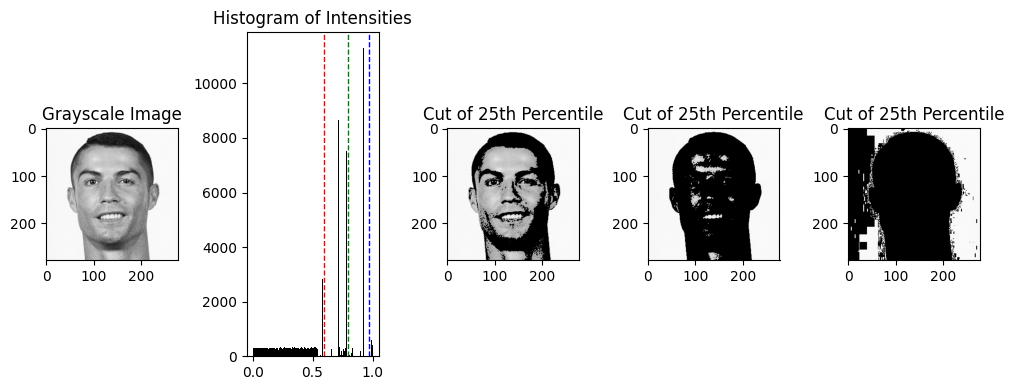

In [64]:
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.color import rgb2gray
import numpy as np

image = imread('cr.jpg')
image_gray = rgb2gray(image)

# Calcular los valores de intensidad para el 25, 50 y 75 percentil
p25 = np.percentile(image_gray, 25)
p50 = np.percentile(image_gray, 50)
p75 = np.percentile(image_gray, 75)

# Crear copias de la imagen en grises para cada umbral
img_p25 = image_gray.copy()
img_p50 = image_gray.copy()
img_p75 = image_gray.copy()

# Aplicar los cortes (cutoff): los píxeles menores al percentil se vuelven negros (0)
img_p25[img_p25 < p25] = 0
img_p50[img_p50 < p50] = 0
img_p75[img_p75 < p75] = 0

# Mostrar resultado
fig, axes = plt.subplots(1, 5, figsize=(10, 4))

axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title('Grayscale Image')

axes[1].hist(imagen_ecualizada.ravel(), bins=256, color='black')
axes[1].axvline(p25, color='r', linestyle='dashed', linewidth=1)
axes[1].axvline(p50, color='g', linestyle='dashed', linewidth=1)
axes[1].axvline(p75, color='b', linestyle='dashed', linewidth=1)
axes[1].set_title('Histogram of Intensities')
    
axes[2].imshow(img_p25, cmap='gray')
axes[2].set_title('Cut of 25th Percentile')
    
axes[3].imshow(img_p50, cmap='gray')
axes[3].set_title('Cut of 25th Percentile')

axes[4].imshow(img_p75, cmap='gray')
axes[4].set_title('Cut of 25th Percentile')

plt.tight_layout()
plt.show()

# Ejercicio 3

¡Los cuadrantes están de vuelta! Debes dividir la imagen `messi.jpg` en cuatro cuadrantes diferentes. Se deben aplicar las siguientes modificaciones:

1. Q0: Nada, imagen RGB original.
2. Q1: Resultado de un *high-pass filter*.
3. Q2: Resultado de un *low-pass filter* en RGB (mostrando los colores).
4. Q3: Canny *edges* del cuadrante.

Pista: `skimage.feature.canny()` espera una imagen en escala de grises, pero no debería ser un problema. Puedes introducir una imagen en escala de grises y obtener una salida también en escala de grises; luego puedes repetir esta salida tres veces para formar los tres canales de una imagen RGB.

La imagen resultante debería verse así:

![](./E3_SideA.png)


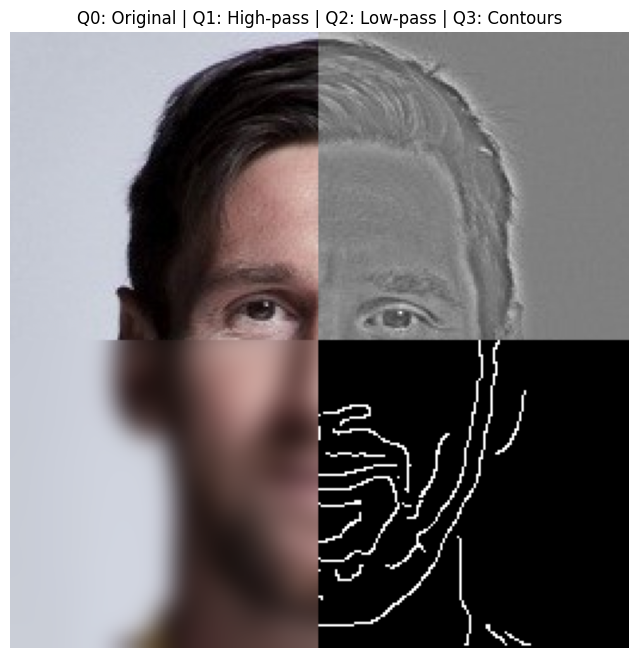

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, feature, img_as_float
from scipy.ndimage import gaussian_filter

img = img_as_float(io.imread('messi.jpg'))

img_gray = color.rgb2gray(img)
height, width = img_gray.shape

result = np.zeros_like(img)

# Q0
result[:height//2, :width//2] = img[:height//2, :width//2]

# Q1
sigma_high = 3
low_pass_gray = gaussian_filter(img_gray, sigma=sigma_high)
high_pass = img_gray - low_pass_gray
high_pass = np.clip(high_pass + 0.5, 0, 1)
result[:height//2, width//2:] = np.stack((high_pass[:height//2, width//2:],)*3, axis=-1)
# Q2
sigma_low = 5
low_pass_rgb = gaussian_filter(img, sigma=[sigma_low, sigma_low, 0])
result[height//2:, :width//2] = low_pass_rgb[height//2:, :width//2]

# Q3
sigma_canny = 2
edges = feature.canny(img_gray, sigma=sigma_canny)

result[height//2:, width//2:] = np.stack((edges[height//2:, width//2:],)*3, axis=-1)

# Mostrar el resultado final
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(result)
ax.set_title("Q0: Original | Q1: High-pass | Q2: Low-pass | Q3: Contours")
ax.axis('off')
plt.show()